# TP : Reprogrammation de LeNet-5 pour la classification des caractères Tifinagh (AMHCD RGB)

**Nom :** Abdelmajid OUCHNI

**Master :** Intelligence Artificielle & Applications (IAA)

**Module :** Deep Learning

**Encadrant :** Dr. Mohamed BENADDY 

## Objectif
Reprogrammer LeNet-5 pour classifier les caractères manuscrits amazighs de la base AMHCD en conservant les images **RGB**. Le notebook produit les résultats nécessaires à l'article : métriques quantitatives, courbes, matrice de confusion, exemples de prédictions et cartes de caractéristiques.



Le notebook vérifie explicitement les labels. Il s'arrête avec un message explicite si le format des labels n'est pas reconnu : il ne crée pas silencieusement une seule classe.

## 1. Importation des bibliothèques

Nous utilisons TensorFlow/Keras pour construire le CNN, OpenCV pour lire les images en RGB, scikit-learn pour diviser les données et calculer les métriques, et Matplotlib/Seaborn pour les visualisations.

In [1]:
import os
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

SEED=42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:",tf.__version__)
print("GPU disponible:",tf.config.list_physical_devices("GPU"))

TensorFlow: 2.19.0
GPU disponible: []


## 2. Configuration des chemins

Les chemins correspondent à ton dossier `data`. Tous les résultats de l'article seront sauvegardés dans le dossier `resultat`, créé automatiquement.

In [2]:
DATA_ROOT=Path(r"C:/Users/mouch/OneDrive/Desktop/data")
IMAGES_DIR=DATA_ROOT/"AMHCD_64"
LABELS_PATH=DATA_ROOT/"labels"
RESULTS_DIR=DATA_ROOT/"resultat"
RESULTS_DIR.mkdir(parents=True,exist_ok=True)

IMAGE_EXTENSIONS={".png",".jpg",".jpeg",".bmp",".tif",".tiff"}

print("Dossier data existe:",DATA_ROOT.exists())
print("Dossier images:",IMAGES_DIR,"| existe:",IMAGES_DIR.exists())
print("Chemin labels:",LABELS_PATH,"| existe:",LABELS_PATH.exists())
print("Dossier résultats:",RESULTS_DIR)
if not IMAGES_DIR.exists():
    raise FileNotFoundError(f"Dossier images introuvable: {IMAGES_DIR}")
if not LABELS_PATH.exists():
    raise FileNotFoundError(f"Dossier/fichier labels introuvable: {LABELS_PATH}")

print("\nContenu de labels:")
if LABELS_PATH.is_dir():
    for p in list(sorted(LABELS_PATH.iterdir()))[:30]:
        print(("DIR " if p.is_dir() else "FILE"),p.name)
    if len(list(LABELS_PATH.iterdir()))>30:
        print("... affichage limité aux 30 premiers éléments")
else:
    print(LABELS_PATH.name,"| taille:",LABELS_PATH.stat().st_size,"octets")

print("\nExemples de contenu de AMHCD_64:")
for p in list(sorted(IMAGES_DIR.iterdir()))[:20]:
    print(("DIR " if p.is_dir() else "FILE"),p.name)

Dossier data existe: True
Dossier images: C:\Users\mouch\OneDrive\Desktop\data\AMHCD_64 | existe: True
Chemin labels: C:\Users\mouch\OneDrive\Desktop\data\labels | existe: True
Dossier résultats: C:\Users\mouch\OneDrive\Desktop\data\resultat

Contenu de labels:
FILE 33-common-latin-tifinagh.txt
FILE sorted-33-common-tifinagh.txt

Exemples de contenu de AMHCD_64:
DIR  ya
DIR  yab
DIR  yach
DIR  yad
DIR  yadd
DIR  yae
DIR  yaf
DIR  yag
DIR  yagh
DIR  yagw
DIR  yah
DIR  yahh
DIR  yaj
DIR  yak
DIR  yakw
DIR  yal
DIR  yam
DIR  yan
DIR  yaq
DIR  yar


## 3. Chargement des images et des labels

Le code prend en charge trois organisations courantes :
1. un sous-dossier par classe dans `AMHCD_64` ;
2. un fichier CSV/TXT/JSON/NPY contenant les labels ;
3. un dossier `labels` contenant un fichier de label par image, avec le même nom de base.

Si ton fichier de labels utilise une autre structure, la cellule affiche une erreur claire. Vérifie alors le contenu affiché par la cellule précédente plutôt que d'entraîner un modèle avec de faux labels.

In [3]:
def list_images(folder):
    return sorted([p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS])

image_paths=list_images(IMAGES_DIR)
if not image_paths:
    raise ValueError(f"Aucune image trouvée dans {IMAGES_DIR}")

def find_label_table(labels_path):
    if labels_path.is_file():
        candidates=[labels_path]
    else:
        candidates=sorted([p for p in labels_path.iterdir() if p.is_file() and p.suffix.lower() in {".csv",".txt",".tsv",".json",".npy"}])
    for p in candidates:
        suffix=p.suffix.lower()
        try:
            if suffix==".csv":
                df=pd.read_csv(p)
            elif suffix==".tsv":
                df=pd.read_csv(p,sep="\t")
            elif suffix==".txt":
                df=pd.read_csv(p,sep=None,engine="python",header=None)
            elif suffix==".json":
                df=pd.read_json(p)
            elif suffix==".npy":
                arr=np.load(p,allow_pickle=True)
                if arr.ndim==1:
                    df=pd.DataFrame({"label":arr})
                else:
                    continue
            else:
                continue
            if len(df)>0:
                return p,df
        except Exception as e:
            print(f"Fichier ignoré ({p.name}): {e}")
    return None,None

records=[]
# Cas A : les noms des sous-dossiers d'images sont les classes.
class_dirs=[p for p in IMAGES_DIR.iterdir() if p.is_dir()]
if class_dirs:
    for class_dir in sorted(class_dirs):
        for image_path in list_images(class_dir):
            records.append({"image_path":str(image_path),"label":class_dir.name})
    source_labels="noms des sous-dossiers"
else:
    # Cas B : labels stockés dans un tableau.
    label_file,label_df=find_label_table(LABELS_PATH)
    if label_file is not None:
        print("Fichier de labels détecté:",label_file)
        print("Colonnes du fichier:",list(label_df.columns))
        # Chercher une colonne de chemin/nom d'image et une colonne de classe.
        normalized={str(c).strip().lower():c for c in label_df.columns}
        image_col=next((normalized[k] for k in ["filename","file_name","image","image_name","path","image_path","file","nom","nom_image"] if k in normalized),None)
        label_col=next((normalized[k] for k in ["label","class","classe","character","character_label","target","y"] if k in normalized),None)
        if label_df.shape[1]==1 and label_col is None:
            label_col=label_df.columns[0]
        if label_col is None:
            raise ValueError("Colonne des labels introuvable dans le fichier. Colonnes détectées: "+str(list(label_df.columns)))
        if image_col is not None:
            lookup={Path(str(p)).name: p for p in image_paths}
            lookup_stem={Path(str(p)).stem: p for p in image_paths}
            for _,row in label_df.iterrows():
                key=str(row[image_col]).strip()
                matched=lookup.get(Path(key).name) or lookup_stem.get(Path(key).stem)
                if matched is not None and pd.notna(row[label_col]):
                    records.append({"image_path":str(matched),"label":str(row[label_col])})
        elif len(label_df)==len(image_paths):
            # Si le fichier contient seulement les labels, on suppose que l'ordre correspond à l'ordre trié des images.
            for image_path,label in zip(image_paths,label_df[label_col].tolist()):
                if pd.notna(label):
                    records.append({"image_path":str(image_path),"label":str(label)})
            print("Attention: labels associés par ordre trié des chemins. Vérifie que cet ordre correspond à celui du dataset.")
        source_labels=str(label_file)
    else:
        # Cas C : un fichier dans labels pour chaque image (nom identique).
        label_files=[p for p in LABELS_PATH.rglob("*") if p.is_file()]
        label_map={p.stem:p for p in label_files}
        for image_path in image_paths:
            lp=label_map.get(image_path.stem)
            if lp is not None:
                try:
                    label=lp.read_text(encoding="utf-8-sig").strip().splitlines()[0].strip()
                    if label:
                        records.append({"image_path":str(image_path),"label":label})
                except Exception:
                    pass
        source_labels="fichiers individuels dans labels"

if not records:
    raise ValueError(
        "Aucun couple image-label n'a été construit. Le notebook n'entraînera pas un modèle avec une seule classe fictive. "
        "Examine les fichiers affichés dans la section 2 et adapte le format de lecture des labels."
    )

labels_df=pd.DataFrame(records).dropna(subset=["label"]).drop_duplicates(subset=["image_path"]).reset_index(drop=True)
labels_df["label"]=labels_df["label"].astype(str).str.strip()
labels_df=labels_df[labels_df["label"]!=""].reset_index(drop=True)

print("Source des labels:",source_labels)
print("Nombre d'images étiquetées:",len(labels_df))
print("Nombre de classes:",labels_df["label"].nunique())
print("Répartition des classes:")
display(labels_df["label"].value_counts().sort_index().to_frame("nombre_images"))
if labels_df["label"].nunique()<2:
    raise ValueError("Une seule classe a été détectée. Le format des labels est incorrect ou le fichier labels n'a pas été associé correctement.")

Source des labels: noms des sous-dossiers
Nombre d'images étiquetées: 25740
Nombre de classes: 33
Répartition des classes:


,nombre_images
label,
ya,780
yab,780
yach,780
yad,780
yadd,780
yae,780
yaf,780
yag,780
yagh,780


## 4. Distribution des classes

Cette visualisation permet de vérifier le nombre d'images de chaque classe.

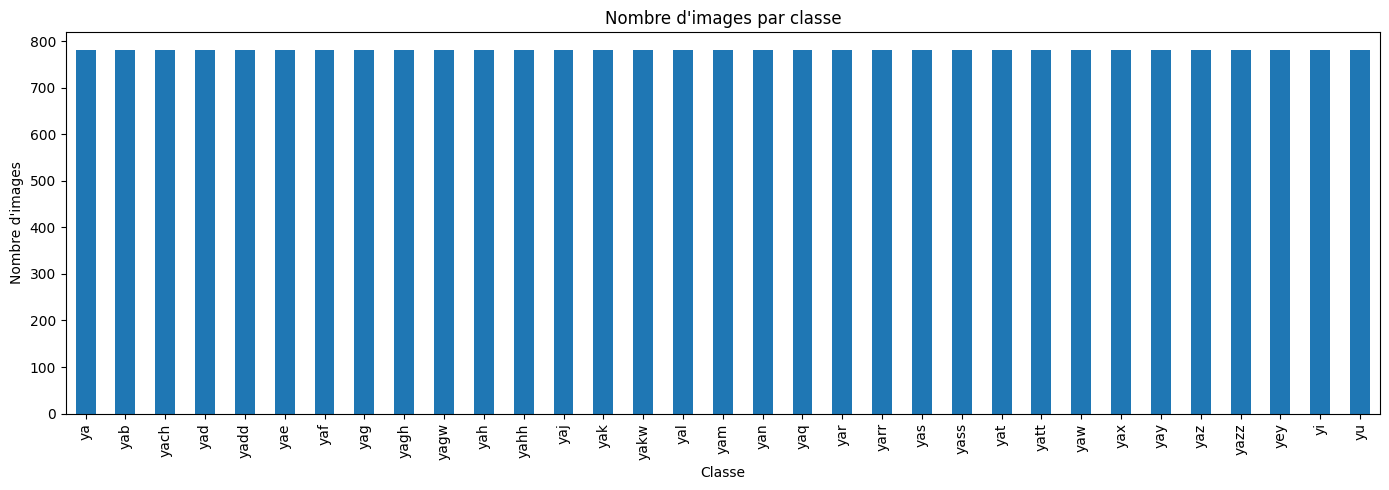

In [4]:
class_counts=labels_df["label"].value_counts().sort_index()
plt.figure(figsize=(14,5))
class_counts.plot(kind="bar")
plt.title("Nombre d'images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(RESULTS_DIR/"distribution_classes.png",dpi=150,bbox_inches="tight")
plt.show()

## 5. Encodage des labels

Chaque classe textuelle est transformée en un entier. Le nombre de neurones de sortie sera égal au nombre réel de classes détectées.

In [5]:
label_encoder=LabelEncoder()
labels_df["label_encoded"]=label_encoder.fit_transform(labels_df["label"])
class_names=label_encoder.classes_
num_classes=len(class_names)
print("Nombre de classes:",num_classes)
print("Classes:",list(class_names))

Nombre de classes: 33
Classes: ['ya', 'yab', 'yach', 'yad', 'yadd', 'yae', 'yaf', 'yag', 'yagh', 'yagw', 'yah', 'yahh', 'yaj', 'yak', 'yakw', 'yal', 'yam', 'yan', 'yaq', 'yar', 'yarr', 'yas', 'yass', 'yat', 'yatt', 'yaw', 'yax', 'yay', 'yaz', 'yazz', 'yey', 'yi', 'yu']


## 6. Prétraitement des images RGB

Les images sont redimensionnées en `32×32` pour correspondre aux dimensions de LeNet-5 décrites dans le TP. Les trois canaux RGB sont conservés et les pixels sont normalisés entre 0 et 1.

In [6]:
IMG_HEIGHT=32
IMG_WIDTH=32
CHANNELS=3

def load_and_preprocess_image(image_path,target_size=(IMG_WIDTH,IMG_HEIGHT)):
    image=cv2.imread(str(image_path),cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Impossible de lire l'image: {image_path}")
    image=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
    image=cv2.resize(image,target_size,interpolation=cv2.INTER_AREA)
    return image.astype(np.float32)/255.0

X=np.stack([load_and_preprocess_image(p) for p in labels_df["image_path"]])
y=labels_df["label_encoded"].to_numpy(dtype=np.int64)
assert len(X)==len(y)
assert X.shape[1:]==(IMG_HEIGHT,IMG_WIDTH,CHANNELS)
print("Forme de X:",X.shape)
print("Forme de y:",y.shape)
print("Valeurs des pixels:",float(X.min()),"à",float(X.max()))

Forme de X: (25740, 32, 32, 3)
Forme de y: (25740,)
Valeurs des pixels: 0.125490203499794 à 1.0


## 7. Division Train / Validation / Test

Nous séparons les données en 60 % pour l'entraînement, 20 % pour la validation et 20 % pour le test. La séparation est stratifiée afin de conserver la proportion des classes. Cette cellule définit `X_train`, `X_val`, `X_test`, `y_train`, `y_val` et `y_test`, nécessaires à l'entraînement.

In [7]:
X_train,X_temp,y_train,y_temp=train_test_split(X,y,test_size=0.40,random_state=SEED,stratify=y)
X_val,X_test,y_val,y_test=train_test_split(X_temp,y_temp,test_size=0.50,random_state=SEED,stratify=y_temp)
print("Train:",X_train.shape,y_train.shape)
print("Validation:",X_val.shape,y_val.shape)
print("Test:",X_test.shape,y_test.shape)
print("Classes dans train:",len(np.unique(y_train)))
print("Classes dans validation:",len(np.unique(y_val)))
print("Classes dans test:",len(np.unique(y_test)))

Train: (15444, 32, 32, 3) (15444,)
Validation: (5148, 32, 32, 3) (5148,)
Test: (5148, 32, 32, 3) (5148,)
Classes dans train: 33
Classes dans validation: 33
Classes dans test: 33


## 7. Visualisation d'exemples

Les titres affichent les vrais labels détectés dans le dossier `labels` ou dans l'organisation du dataset.

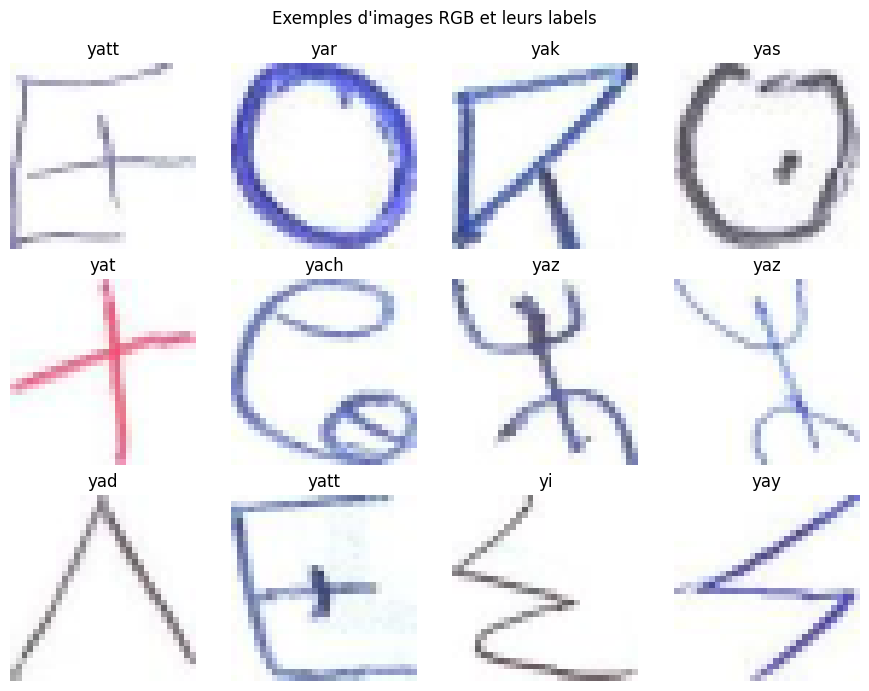

In [8]:
n_show=min(12,len(X))
indices=np.random.choice(len(X),size=n_show,replace=False)
fig,axes=plt.subplots(3,4,figsize=(9,7))
for ax,idx in zip(axes.ravel(),indices):
    ax.imshow(X[idx])
    ax.set_title(str(class_names[y[idx]]))
    ax.axis("off")
for ax in axes.ravel()[n_show:]:
    ax.axis("off")
plt.suptitle("Exemples d'images RGB et leurs labels")
plt.tight_layout()
plt.savefig(RESULTS_DIR/"exemples_images_labels.png",dpi=150,bbox_inches="tight")
plt.show()

## 8. Architecture de LeNet-5 adaptée au RGB

L'architecture suit les dimensions décrites dans le sujet : convolution `5×5` avec 6 filtres, average pooling `2×2`, convolution `5×5` avec 16 filtres, average pooling `2×2`, puis couches denses de 120 et 84 neurones. La dernière couche contient `num_classes` neurones.

L'entrée comporte trois canaux au lieu d'un, car les images sont conservées en RGB. Les convolutions utilisent `padding="valid"` pour reproduire les dimensions indiquées dans le sujet. La sortie fournit des logits ; la fonction de perte applique ensuite Softmax de manière numériquement stable.

In [9]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, AveragePooling2D, Flatten, Dense
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy

def build_lenet5(input_shape=(32, 32, 3),num_classes=33):
    model=Sequential([
        Input(shape=input_shape, name="input_rgb"),
        Conv2D(6, kernel_size=(5,5),strides=1,padding="valid",activation="tanh",name="C1"),
        AveragePooling2D(pool_size=(2,2),strides=2,name="S2"),
        Conv2D(16, kernel_size=(5,5),strides=1,padding="valid",activation="tanh",name="C3"),
        AveragePooling2D(pool_size=(2,2), strides=2,name="S4"),
        Flatten(name="flatten"),
        Dense(120, activation="tanh",name="C5"),
        Dense(84, activation="tanh",name="F6"),
        Dense(num_classes, activation=None, name="output_logits")
    ], name="LeNet5_AMHCD_RGB")
    return model

model = build_lenet5(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS),
    num_classes=num_classes
)
model.summary()

Model: "LeNet5_AMHCD_RGB"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ C1 (Conv2D)                     │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S2 (AveragePooling2D)           │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3 (Conv2D)                     │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S4 (AveragePooling2D)           │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5 (Dense)                      │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ F6 (Dense)                      │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_logits (Dense)           │ (None, 33)             │         2,805 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,961 (249.85 KB)

 Trainable params: 63,961 (249.85 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Vérification des dimensions

Pour une convolution `valid`, la dimension de sortie est `H_out = H_in - K + 1` lorsque le stride vaut 1. Pour le pooling `2×2` avec stride 2, la dimension est divisée par 2.

In [10]:
for layer in model.layers:
    print(f"{layer.name:18s}->{layer.output.shape}")

C1                ->(None, 28, 28, 6)
S2                ->(None, 14, 14, 6)
C3                ->(None, 10, 10, 16)
S4                ->(None, 5, 5, 16)
flatten           ->(None, 400)
C5                ->(None, 120)
F6                ->(None, 84)
output_logits     ->(None, 33)


## 10. Configuration de l'entraînement

Nous définissons une fonction paramétrable pour choisir l'optimiseur. Nous commencerons avec **Adam**, puis nous pourrons comparer avec **SGD** en gardant les mêmes ensembles de données.

In [11]:
def compile_model(model, optimizer_name="adam", learning_rate=0.001):
    name = optimizer_name.lower()
    if name == "adam":
        optimizer = Adam(learning_rate=learning_rate)
    elif name == "sgd":
        optimizer = SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError("optimizer_name doit être 'adam' ou 'sgd'.")

    model.compile(
        optimizer=optimizer,
        loss=SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"]
    )
    return model

model = compile_model(model, optimizer_name="adam", learning_rate=0.001)

## 11. Entraînement et validation

L'entraînement utilise les données Train. À chaque époque, les performances sont également mesurées sur Validation. `EarlyStopping` arrête l'entraînement si la perte de validation ne s'améliore plus et restaure les meilleurs poids.

In [12]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

EPOCHS = 30
BATCH_SIZE = 64

callbacks = [
    EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.3114 - loss: 2.7133 - val_accuracy: 0.8324 - val_loss: 0.7120 - learning_rate: 0.0010
Epoch 2/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8663 - loss: 0.5736 - val_accuracy: 0.8932 - val_loss: 0.4338 - learning_rate: 0.0010
Epoch 3/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9133 - loss: 0.3599 - val_accuracy: 0.9132 - val_loss: 0.3383 - learning_rate: 0.0010
Epoch 4/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9357 - loss: 0.2678 - val_accuracy: 0.9264 - val_loss: 0.2801 - learning_rate: 0.0010
Epoch 5/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9486 - loss: 0.2089 - val_accuracy: 0.9355 - val_loss: 0.2397 - learning_rate: 0.0010
Epoch 6/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9572 - loss: 0.1690 - val_accuracy: 0.9431 - val_loss: 0.2130 - learning_rate: 0.0010
Epoch 7/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9657 - loss: 0.

## 12. Courbes de Loss et d'Accuracy

Les courbes permettent de comparer les performances d'entraînement et de validation et de repérer un éventuel surapprentissage.

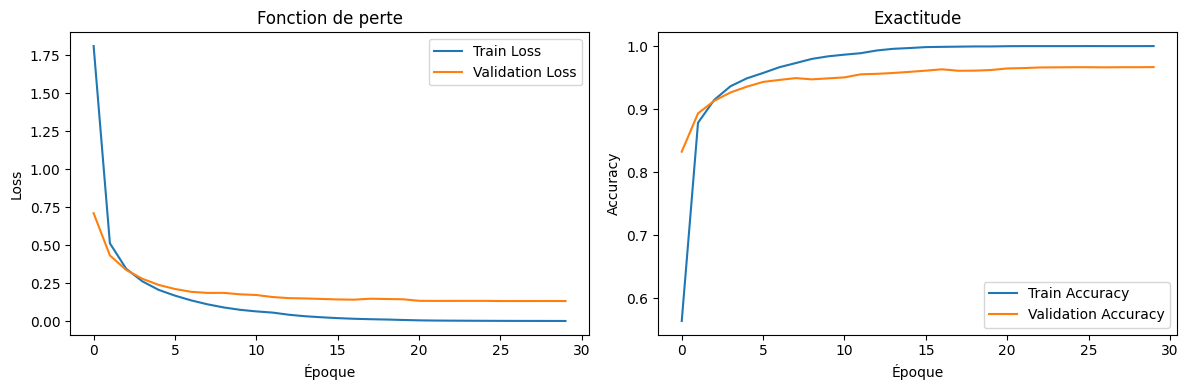

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")
axes[0].set_title("Fonction de perte")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="Train Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Exactitude")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR/"lenet5_loss_accuracy.png",dpi=150,bbox_inches="tight")
plt.show()

## 13. Évaluation finale sur le test

L'ensemble de test permet d'estimer la capacité de généralisation du modèle sur des images qui n'ont pas servi à l'entraînement ni au choix des hyperparamètres.

In [14]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
logits = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
y_pred = np.argmax(logits, axis=1)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4%}")
print("\nRapport de classification :")
report=classification_report(
    y_test,y_pred,
    labels=np.arange(num_classes),
    target_names=[str(c) for c in class_names],
    zero_division=0
)
print(report)
(RESULTS_DIR/"classification_report.txt").write_text(report,encoding="utf-8")
pd.DataFrame([{"test_loss":float(test_loss),"test_accuracy":float(test_accuracy),"num_classes":int(num_classes),"test_samples":int(len(y_test))}]).to_csv(RESULTS_DIR/"metrics_test.csv",index=False)

Test Loss     : 0.1166
Test Accuracy : 96.8920%

Rapport de classification :
              precision    recall  f1-score   support

          ya       0.99      0.99      0.99       156
         yab       0.96      0.99      0.98       156
        yach       0.98      0.99      0.98       156
         yad       0.97      0.99      0.98       156
        yadd       0.96      0.96      0.96       156
         yae       0.93      0.99      0.96       156
         yaf       0.99      0.99      0.99       156
         yag       0.99      0.99      0.99       156
        yagh       0.99      0.96      0.97       156
        yagw       0.97      0.96      0.96       156
         yah       1.00      0.96      0.98       156
        yahh       0.99      0.98      0.98       156
         yaj       0.96      0.97      0.96       156
         yak       0.97      0.96      0.97       156
        yakw       0.96      0.96      0.96       156
         yal       0.94      0.97      0.96       156
    

## 14. Matrice de confusion

La matrice de confusion montre quelles classes sont correctement reconnues et quelles classes sont confondues entre elles.

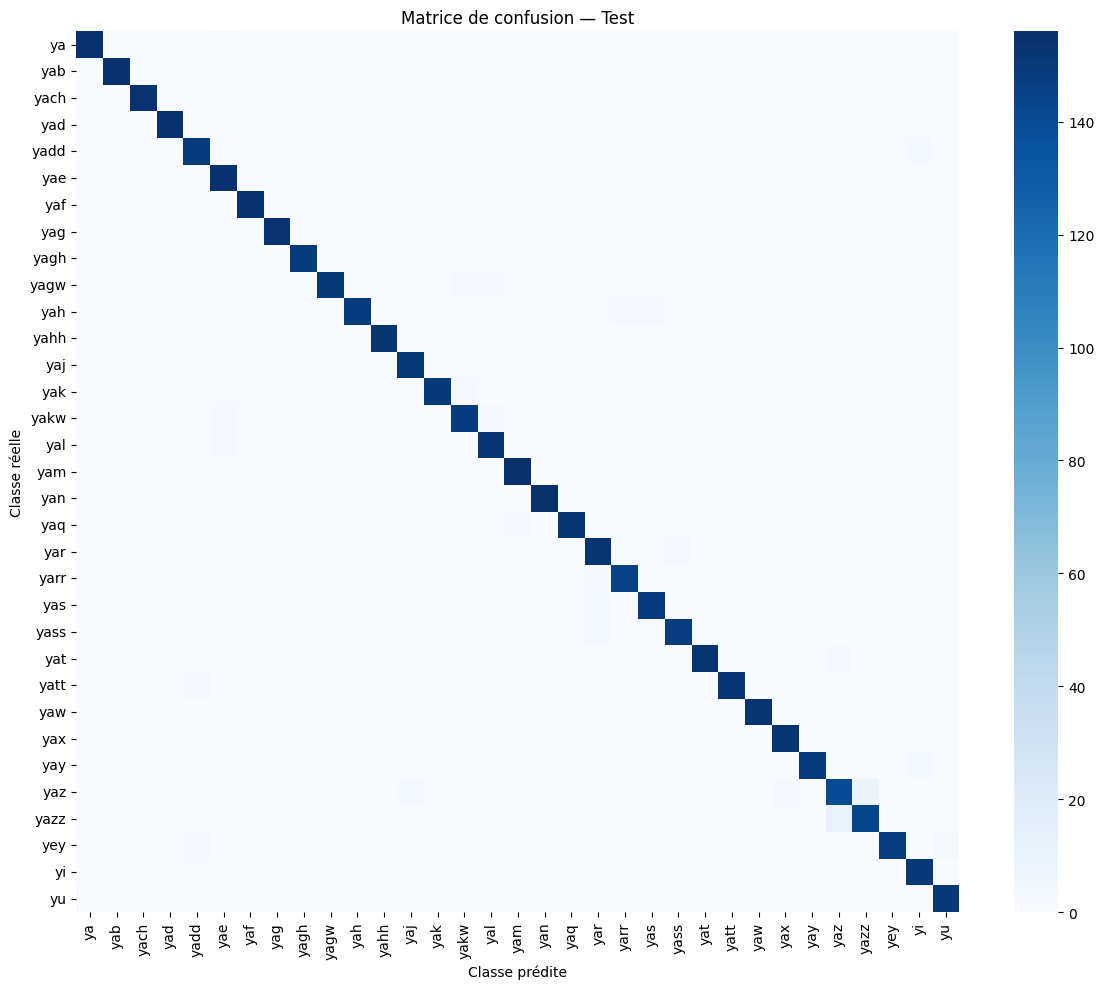

In [15]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(num_classes))
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", annot=False, xticklabels=class_names, yticklabels=class_names)
plt.title("Matrice de confusion — Test")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR/"lenet5_confusion_matrix.png",dpi=150,bbox_inches="tight")
plt.show()

## 15. Résultats qualitatifs : exemples de prédictions

Nous affichons des images de test, leur classe réelle et leur classe prédite. La couleur du titre indique si la prédiction est correcte.

## 15. Résultats qualitatifs : exemples de prédictions

Le titre indique le label réel et le label prédit. Vert = prédiction correcte ; rouge = erreur.

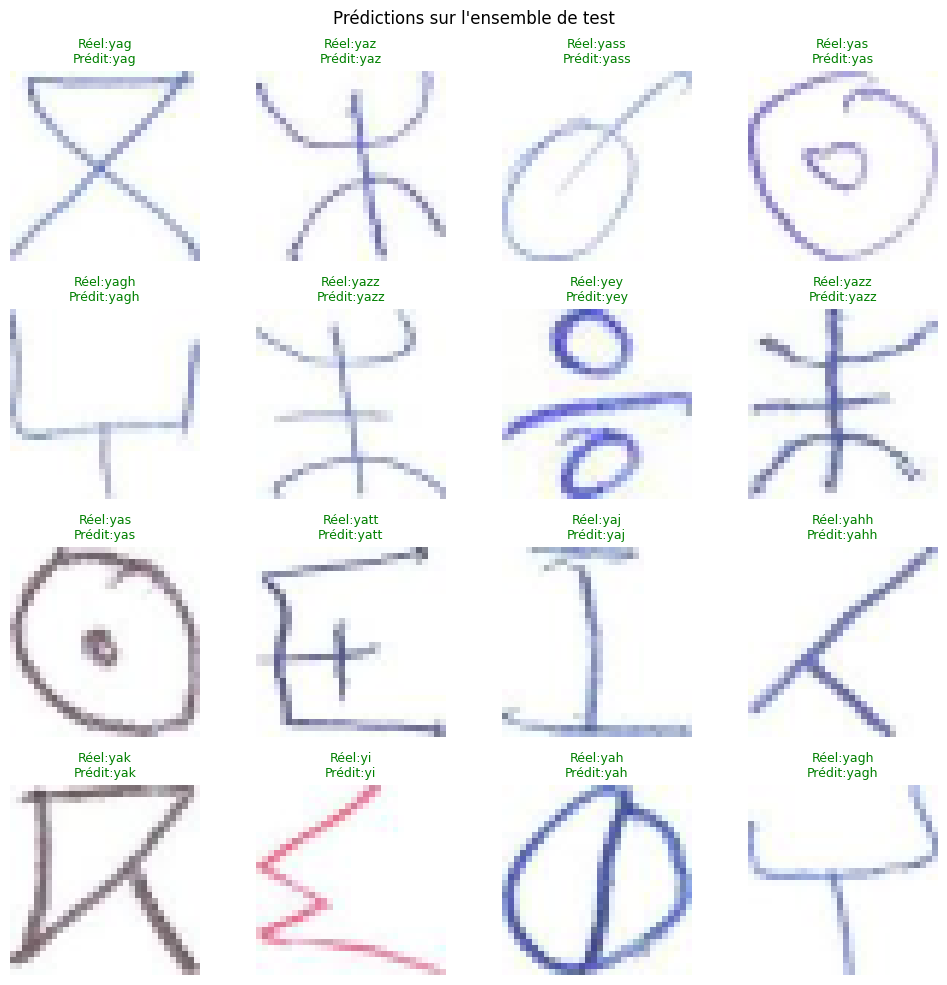

In [16]:
n_show=min(16,len(X_test))
indices=np.random.choice(len(X_test),size=n_show,replace=False)
fig,axes=plt.subplots(4,4,figsize=(10,10))
for ax,idx in zip(axes.ravel(),indices):
    true_label=class_names[y_test[idx]]
    pred_label=class_names[y_pred[idx]]
    ax.imshow(X_test[idx])
    ax.set_title(f"Réel:{true_label}\nPrédit:{pred_label}",color="green" if y_test[idx]==y_pred[idx] else "red",fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[n_show:]:
    ax.axis("off")
plt.suptitle("Prédictions sur l'ensemble de test")
plt.tight_layout()
plt.savefig(RESULTS_DIR/"predictions_test.png",dpi=150,bbox_inches="tight")
plt.show()

C:\Users\mouch\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\keras\src\models\functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_rgb']
Received: inputs=Tensor(shape=(1, 32, 32, 3))
  warnings.warn(msg)


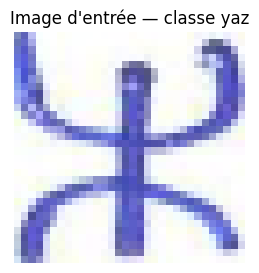

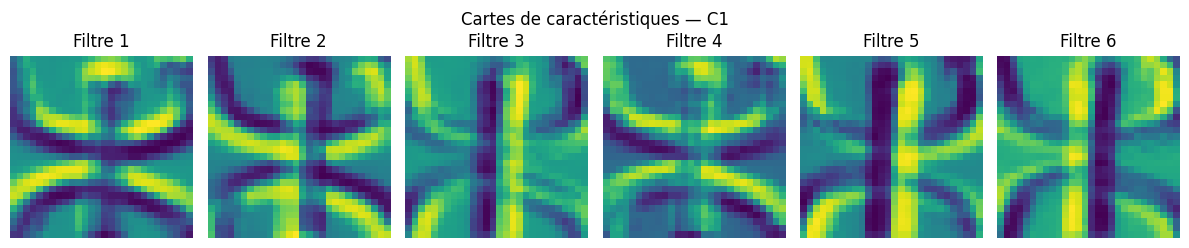

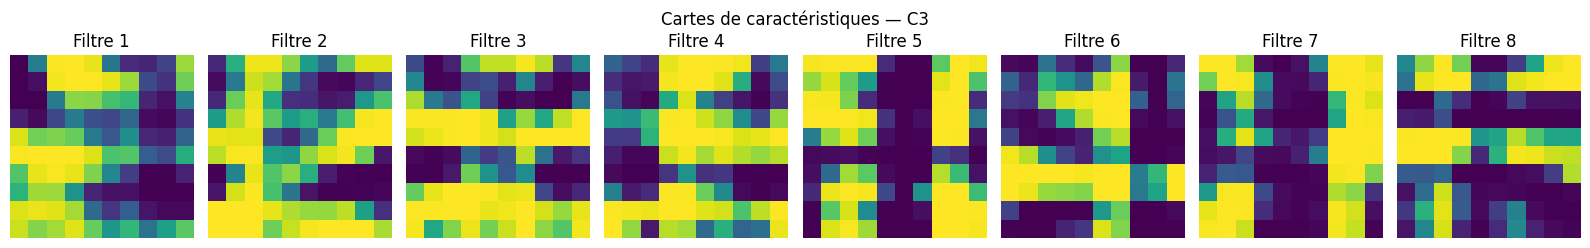

In [17]:
conv_layers = [layer for layer in model.layers if isinstance(layer, Conv2D)]
feature_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[layer.output for layer in conv_layers]
)

sample = X_test[0:1]
feature_maps = feature_model.predict(sample, verbose=0)

plt.figure(figsize=(3, 3))
plt.imshow(X_test[0])
plt.title(f"Image d'entrée — classe {class_names[y_test[0]]}")
plt.axis("off")
plt.savefig(RESULTS_DIR/"image_entree_feature_maps.png",dpi=150,bbox_inches="tight")
plt.show()

for layer, fmap in zip(conv_layers, feature_maps):
    n_features = min(fmap.shape[-1], 8)
    fig, axes = plt.subplots(1, n_features, figsize=(2*n_features, 2.5))
    if n_features == 1:
        axes = [axes]
    for i, ax in enumerate(axes):
        ax.imshow(fmap[0, :, :, i], cmap="viridis")
        ax.set_title(f"Filtre {i+1}")
        ax.axis("off")
    fig.suptitle(f"Cartes de caractéristiques — {layer.name}")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR/f"feature_maps_{layer.name}.png",dpi=150,bbox_inches="tight")
    plt.show()

## 17. Comparaison expérimentale des optimiseurs : SGD et Adam

Cette partie entraîne **deux nouveaux modèles LeNet-5 identiques** : l'un avec SGD (momentum = 0,9 ; taux initial = 0,01), l'autre avec Adam (taux initial = 0,001). Les deux utilisent les mêmes partitions Train/Validation/Test, la même taille de batch et les mêmes callbacks. Une graine fixe améliore la reproductibilité. Les taux d'apprentissage initiaux sont des réglages de départ raisonnables, mais ne constituent pas une garantie d'optimalité.

Les métriques de test sont calculées après restauration des meilleurs poids selon la perte de validation. Le temps d'entraînement, le nombre d'époques, la perte, l'accuracy et les scores macro Precision/Recall/F1 sont enregistrés. Exécutez la cellule suivante pour obtenir les résultats réels ; ne recopiez pas de valeurs avant son exécution.

In [18]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import time

# Même architecture, mêmes données et mêmes callbacks pour comparer les optimiseurs.
EPOCHS_COMPARISON=30
BATCH_SIZE_COMPARISON=64

def train_with_optimizer(optimizer_name, learning_rate, epochs=EPOCHS_COMPARISON):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    comparison_model=build_lenet5(
        input_shape=(IMG_HEIGHT,IMG_WIDTH,CHANNELS),
        num_classes=num_classes
    )
    compile_model(comparison_model,optimizer_name,learning_rate)

    callbacks=[
        EarlyStopping(monitor="val_loss",patience=6,restore_best_weights=True,verbose=1),
        ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=3,min_lr=1e-6,verbose=1)
    ]

    start=time.time()
    comparison_history=comparison_model.fit(
        X_train,y_train,
        validation_data=(X_val,y_val),
        epochs=epochs,
        batch_size=BATCH_SIZE_COMPARISON,
        callbacks=callbacks,
        verbose=1
    )
    training_seconds=time.time()-start

    test_loss,_=comparison_model.evaluate(X_test,y_test,batch_size=BATCH_SIZE_COMPARISON,verbose=0)
    logits=comparison_model.predict(X_test,batch_size=BATCH_SIZE_COMPARISON,verbose=0)
    y_pred_optimizer=np.argmax(logits,axis=1)
    precision,recall,f1,_=precision_recall_fscore_support(
        y_test,y_pred_optimizer,average="macro",zero_division=0
    )

    result={
        "Optimiseur":optimizer_name.upper(),
        "Learning rate initial":learning_rate,
        "Époques exécutées":len(comparison_history.history["loss"]),
        "Temps entraînement (s)":round(training_seconds,2),
        "Test Loss":float(test_loss),
        "Test Accuracy":float(accuracy_score(y_test,y_pred_optimizer)),
        "Macro Precision":float(precision),
        "Macro Recall":float(recall),
        "Macro F1":float(f1)
    }
    comparison_model.save(RESULTS_DIR/f"lenet5_{optimizer_name.lower()}_amhcd_rgb.keras")
    return comparison_model,comparison_history,result,y_pred_optimizer

comparison_runs={}
comparison_rows=[]
for optimizer_name,learning_rate in [("SGD",0.01),("Adam",0.001)]:
    print(f"\n===== Entraînement avec {optimizer_name} (lr={learning_rate}) =====")
    trained_model,trained_history,result,y_pred_optimizer=train_with_optimizer(optimizer_name,learning_rate)
    comparison_runs[optimizer_name]={
        "model":trained_model,
        "history":trained_history,
        "y_pred":y_pred_optimizer
    }
    comparison_rows.append(result)

comparison_df=pd.DataFrame(comparison_rows)
display(comparison_df.round(4))
comparison_df.to_csv(RESULTS_DIR/"comparaison_SGD_Adam.csv",index=False)
print("Comparaison enregistrée :",RESULTS_DIR/"comparaison_SGD_Adam.csv")



===== Entraînement avec SGD (lr=0.01) =====

Epoch 1/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.1777 - loss: 3.1155 - val_accuracy: 0.8044 - val_loss: 0.9481 - learning_rate: 0.0100
Epoch 2/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8359 - loss: 0.7595 - val_accuracy: 0.8716 - val_loss: 0.5536 - learning_rate: 0.0100
Epoch 3/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8992 - loss: 0.4367 - val_accuracy: 0.9128 - val_loss: 0.3687 - learning_rate: 0.0100
Epoch 4/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9255 - loss: 0.3197 - val_accuracy: 0.9244 - val_loss: 0.3079 - learning_rate: 0.0100
Epoch 5/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9396 - loss: 0.2481 - val_accuracy: 0.9320 - val_loss: 0.2631 - learning_rate: 0.0100
Epoch 6/30
242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9524 - loss: 0.2005 - val_accuracy: 0.9444 - val_loss: 0.2179 - learning_rate: 0.0100
Epoch 7/30
242/242 ━━━━━━━━━━━━━━━━━

,Optimiseur,Learning rate initial,Époques exécutées,Temps entraînement (s),Test Loss,Test Accuracy,Macro Precision,Macro Recall,Macro F1
0,SGD,0.010,30,108.70,0.0773,0.9794,0.9796,0.9794,0.9794
1,ADAM,0.001,30,108.65,0.1166,0.9689,0.9692,0.9689,0.9689


Comparaison enregistrée : C:\Users\mouch\OneDrive\Desktop\data\resultat\comparaison_SGD_Adam.csv


## 18. Courbes comparatives et tableau des résultats

Les courbes de validation permettent de comparer la vitesse de convergence et la généralisation de SGD et Adam. Les métriques finales proviennent du même ensemble de test.

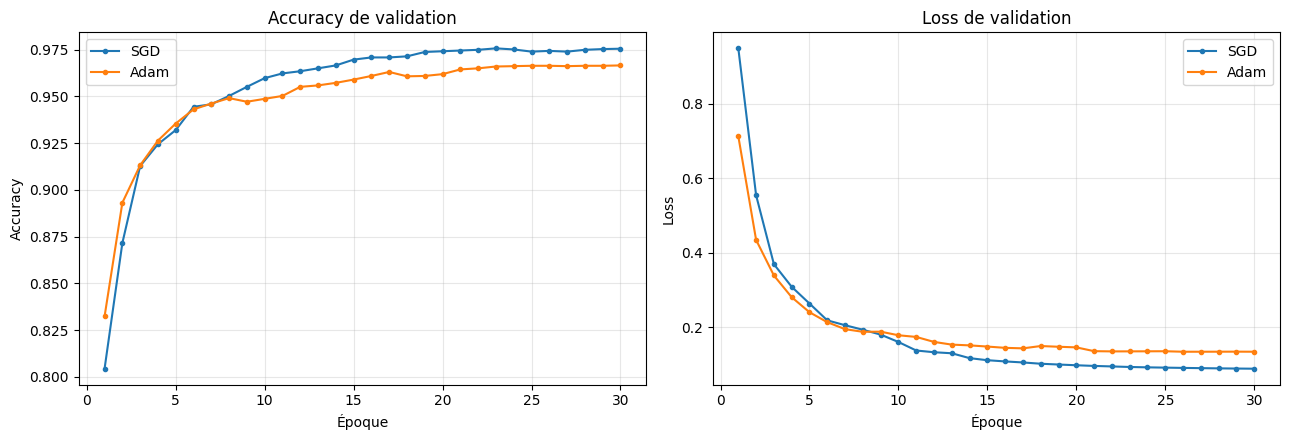

Figures et historiques enregistrés dans : C:\Users\mouch\OneDrive\Desktop\data\resultat


In [19]:
# Comparaison graphique de la perte et de l'accuracy de validation
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for optimizer_name,run in comparison_runs.items():
    hist=run["history"].history
    axes[0].plot(range(1,len(hist["val_accuracy"])+1),hist["val_accuracy"],marker="o",markersize=3,label=optimizer_name)
    axes[1].plot(range(1,len(hist["val_loss"])+1),hist["val_loss"],marker="o",markersize=3,label=optimizer_name)
axes[0].set_title("Accuracy de validation")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Accuracy")
axes[1].set_title("Loss de validation")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Loss")
for ax in axes:
    ax.grid(True,alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR/"comparaison_SGD_Adam.png",dpi=160,bbox_inches="tight")
plt.show()

# Sauvegarde des historiques d'entraînement pour analyse ultérieure
history_rows=[]
for optimizer_name,run in comparison_runs.items():
    hist=run["history"].history
    for epoch in range(len(hist["loss"])):
        history_rows.append({
            "Optimiseur":optimizer_name,
            "Époque":epoch+1,
            "Train Loss":hist["loss"][epoch],
            "Validation Loss":hist["val_loss"][epoch],
            "Train Accuracy":hist["accuracy"][epoch],
            "Validation Accuracy":hist["val_accuracy"][epoch]
        })
pd.DataFrame(history_rows).to_csv(RESULTS_DIR/"historiques_SGD_Adam.csv",index=False)
print("Figures et historiques enregistrés dans :",RESULTS_DIR)

In [20]:
# Tableau compact du modèle principal (entraînement de la section 11)
results_df=pd.DataFrame([{
    "Modèle":"LeNet-5 RGB",
    "Optimiseur":"Adam",
    "Test Loss":float(test_loss),
    "Test Accuracy":float(test_accuracy),
    "Nombre de classes":int(num_classes),
    "Taille entrée":f"{IMG_HEIGHT}x{IMG_WIDTH}x{CHANNELS}"
}])
display(results_df)
results_df.to_csv(RESULTS_DIR/"lenet5_results.csv",index=False)

# Le tableau de comparaison SGD/Adam est généré dans la section 17.


,Modèle,Optimiseur,Test Loss,Test Accuracy,Nombre de classes,Taille entrée
0,LeNet-5 RGB,Adam,0.116568,0.96892,33,32x32x3


## 19. Sauvegarde du modèle et des résultats

Le modèle sauvegardé pourra être rechargé ultérieurement sans refaire l'entraînement.

In [21]:
model.save(RESULTS_DIR/"lenet5_amhcd_rgb.keras")
print("Modèle principal sauvegardé :",RESULTS_DIR/"lenet5_amhcd_rgb.keras")
print("Résultats et figures sauvegardés dans :",RESULTS_DIR)
print("Pour la comparaison SGD/Adam, exécuter les sections 17 et 18.")


Modèle principal sauvegardé : C:\Users\mouch\OneDrive\Desktop\data\resultat\lenet5_amhcd_rgb.keras
Résultats et figures sauvegardés dans : C:\Users\mouch\OneDrive\Desktop\data\resultat
Pour la comparaison SGD/Adam, exécuter les sections 17 et 18.


## 20. Conclusion

Après l'exécution du notebook, rédigez la conclusion en vous appuyant sur les résultats mesurés : accuracy et loss sur le test, classes les mieux reconnues, confusions principales, écart entre entraînement et validation, et différence entre Adam et SGD si la comparaison a été exécutée.

## Structure suggérée de l'article IMRAD

- **Introduction :** contexte de la reconnaissance des caractères Tifinagh et objectif du travail.
- **Méthodes :** description d'AMHCD, prétraitement RGB, division des données, architecture LeNet-5, fonctions de perte et optimiseurs.
- **Résultats :** tableau des métriques, courbes d'apprentissage, matrice de confusion, exemples de prédictions et cartes de caractéristiques.
- **Discussion :** interprétation des résultats, erreurs fréquentes, surapprentissage éventuel et limites.
- **Conclusion :** bilan et pistes d'amélioration.

**Important :** le notebook est préparé pour l'organisation de dossiers `AMHCD_64/<classe>/<image>`. Vérifiez `DATA_DIR` avant d'exécuter les cellules. Si votre dataset est organisé différemment, le code de chargement devra être adapté.